In [1]:
import pandas as pd
import numpy as  np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score,RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report,accuracy_score, confusion_matrix, f1_score

import joblib 

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('dataset.csv')

In [3]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.shape

(48895, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [6]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


<Axes: xlabel='room_type', ylabel='count'>

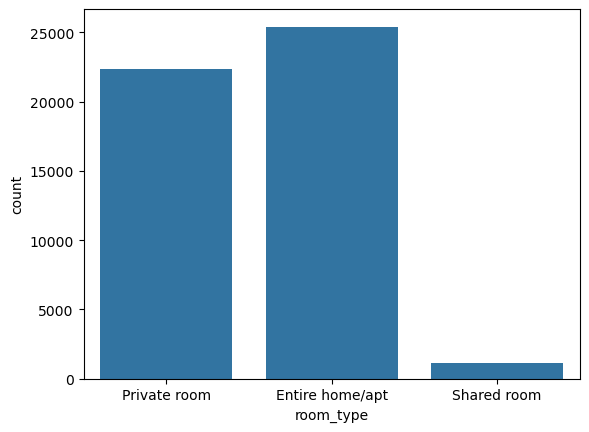

In [9]:
sns.countplot(x = df['room_type'])

In [10]:
num_cols = df.select_dtypes(include = 'number').columns

num_cols = num_cols.drop(['id','host_id'])
print(num_cols)

Index(['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')


array([[<Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'longitude'}>],
       [<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>],
       [<Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>],
       [<Axes: >, <Axes: >]], dtype=object)

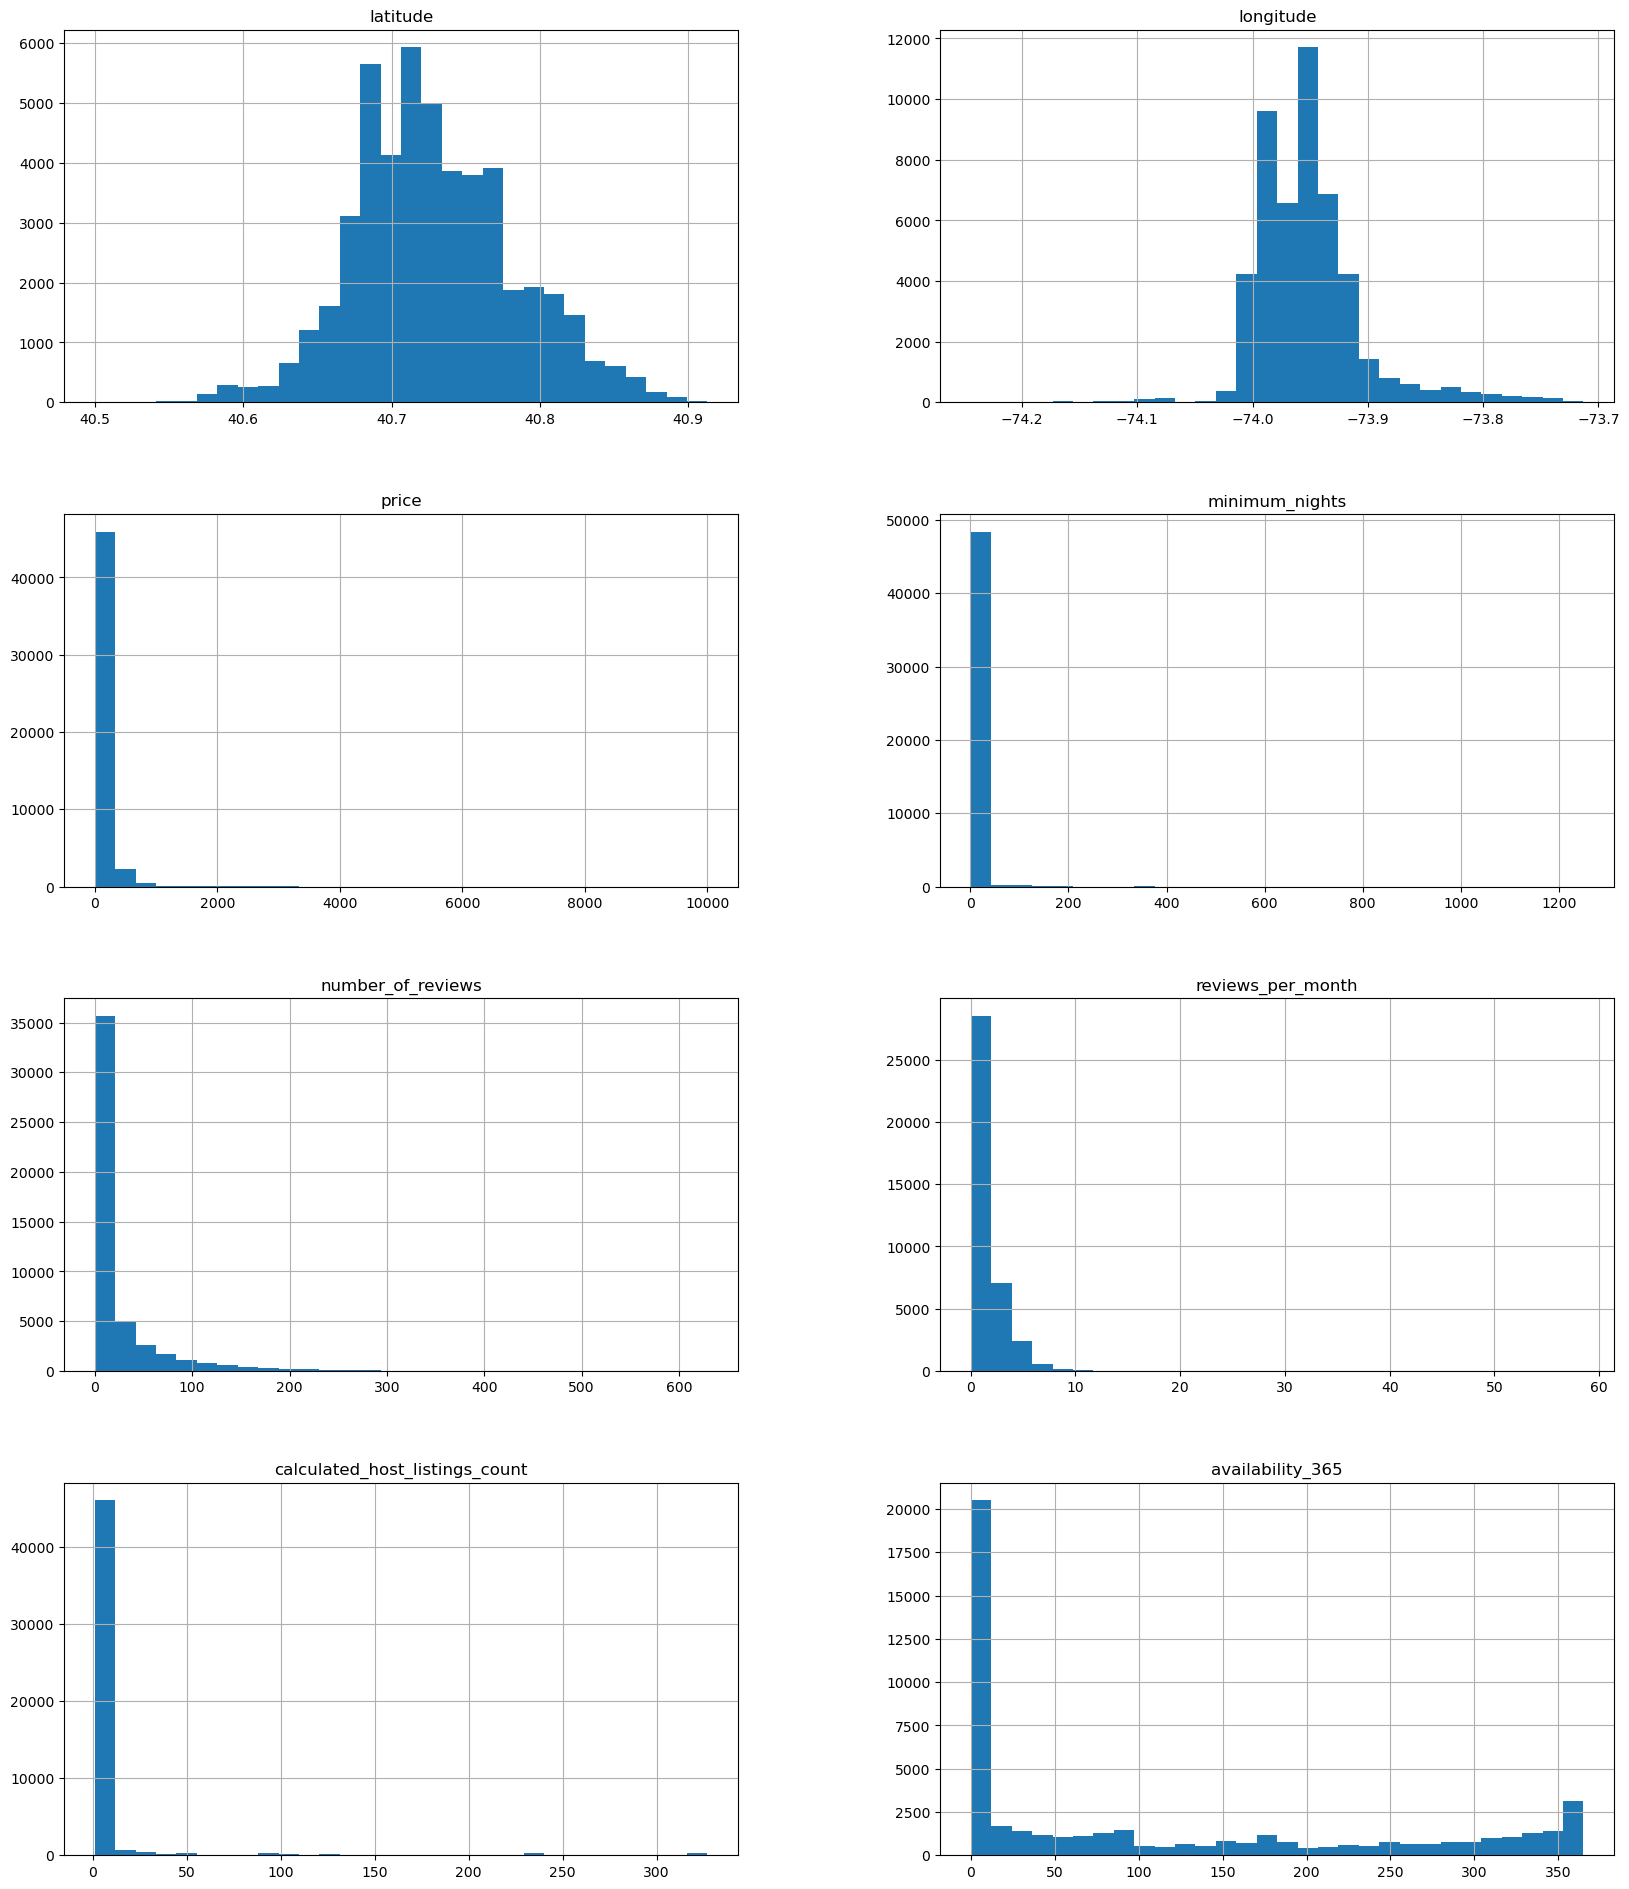

In [11]:
df[num_cols].hist(bins=30, figsize=(20,30), layout=(5,2))

<Axes: xlabel='room_type', ylabel='price'>

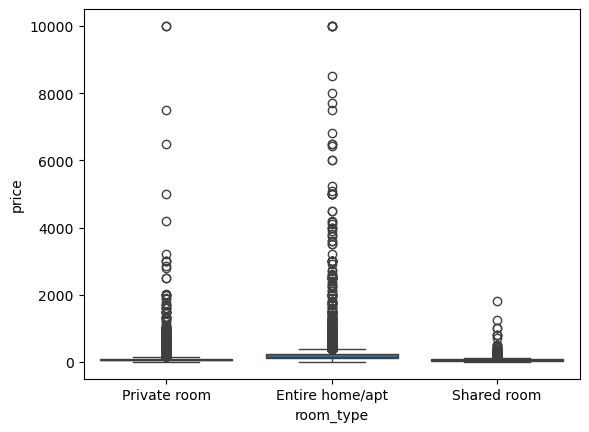

In [12]:
sns.boxplot(x=df['room_type'],y=df['price'])

<Axes: >

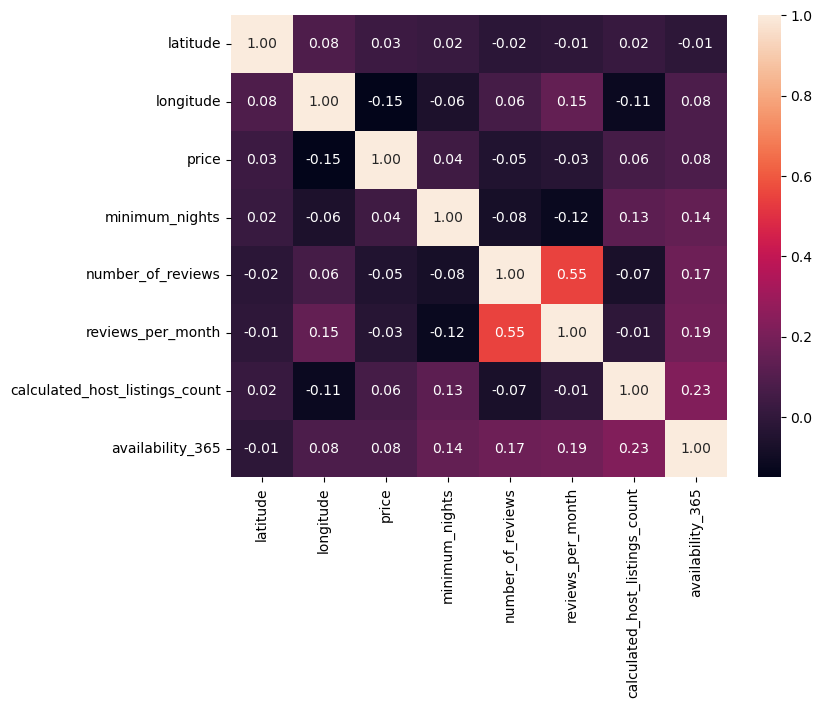

In [13]:
plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols].corr(),annot=True,fmt=".2f")

<Axes: xlabel='longitude', ylabel='latitude'>

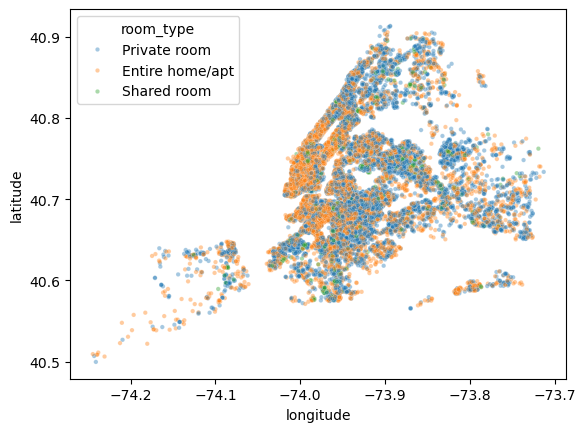

In [14]:
sns.scatterplot(x=df['longitude'],y=df['latitude'], hue=df['room_type'],alpha=0.4,s=10)

In [15]:
df[num_cols].skew()

latitude                           0.237167
longitude                          1.284210
price                             19.118939
minimum_nights                    21.827275
number_of_reviews                  3.690635
reviews_per_month                  3.130189
calculated_host_listings_count     7.933174
availability_365                   0.763408
dtype: float64

In [16]:
train_df = df.drop(columns=['id','name','host_name','last_review'])

In [17]:
# No reviews yet -> 0 reviews per month. not missing
train_df['reviews_per_month'] =  train_df['reviews_per_month'].fillna(0)

In [18]:
price_cap = train_df['price'].quantile(0.99)
train_df['price'] = train_df['price'].clip(upper=price_cap)

nights_cap = train_df['minimum_nights'].quantile(0.99)
train_df['minimum_nights'] = train_df['minimum_nights'].clip(upper=nights_cap)

In [19]:
x = train_df.drop('room_type', axis = 1)
y = train_df['room_type']

x_train,x_test,y_train,y_test = train_test_split(x,y, stratify=y, test_size = 0.2, random_state=42)

In [20]:
num_cols = ['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count','availability_365']

cate_cols = ['neighbourhood_group','neighbourhood']

In [21]:
numeric_pipeline = Pipeline(steps=[
    ('impute',SimpleImputer(strategy='median')),
    ('skewness',PowerTransformer(method='yeo-johnson')),
    ('scale', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('impute',SimpleImputer(strategy='most_frequent')),
    ('encode',OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('numerical', numeric_pipeline, num_cols),
    ('categorical', categorical_pipeline, cate_cols)
])

In [22]:
preprocessor

,transformers,"[('numerical', ...), ('categorical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [23]:
models = {
    'Logistic Regression' : LogisticRegression(class_weight='balanced',random_state=42),
    'Decision Tree' : DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest' : RandomForestClassifier(class_weight='balanced',random_state=42),
    'Gradient Boosting' : GradientBoostingClassifier(random_state=42)
}

In [24]:
for name, model in models.items():
    pipe =Pipeline(steps=[('preprocessor',preprocessor),('classifier',model)])

    accuracy = cross_val_score(pipe,x_train,y_train,cv=3,scoring='accuracy')
    macrof1 = cross_val_score(pipe,x_train,y_train,cv=3,scoring='f1_macro')

    print(f"{name} -> Accuracy: {accuracy.mean():.3f}, F1: {macrof1.mean():.3f}")

Logistic Regression -> Accuracy: 0.730, F1: 0.579
Decision Tree -> Accuracy: 0.787, F1: 0.654
Random Forest -> Accuracy: 0.852, F1: 0.717
Gradient Boosting -> Accuracy: 0.850, F1: 0.706


In [25]:
pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced'))
])

param_distribution ={
    'classifier__n_estimators' : [100,200,300],
    'classifier__max_depth' : [8,12,15,20, None],
    'classifier__min_samples_split' : [2,5,10]
}

search = RandomizedSearchCV(
    estimator = pipeline,
    param_distributions = param_distribution,
    n_iter = 10,
    cv = 3,
    scoring = "f1_macro",
    random_state = 42
)
search.fit(x_train,y_train)

,estimator,Pipeline(step...'balanced'))])
,param_distributions,"{'classifier__max_depth': [8, 12, ...], 'classifier__min_samples_split': [2, 5, ...], 'classifier__n_estimators': [100, 200, ...]}"
,n_iter,10
,scoring,'f1_macro'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [26]:
print('Best Parameters:', search.best_params_)
print("Best CV Macro-F1:",search.best_score_ )

Best Parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__max_depth': None}
Best CV Macro-F1: 0.7346273855584795


In [27]:
pipeline = search.best_estimator_
y_pred = pipeline.predict(x_test)
print(classification_report(y_test, y_pred))

                 precision    recall  f1-score   support

Entire home/apt       0.88      0.88      0.88      5082
   Private room       0.84      0.86      0.85      4465
    Shared room       0.83      0.39      0.53       232

       accuracy                           0.86      9779
      macro avg       0.85      0.71      0.75      9779
   weighted avg       0.86      0.86      0.86      9779



<Axes: >

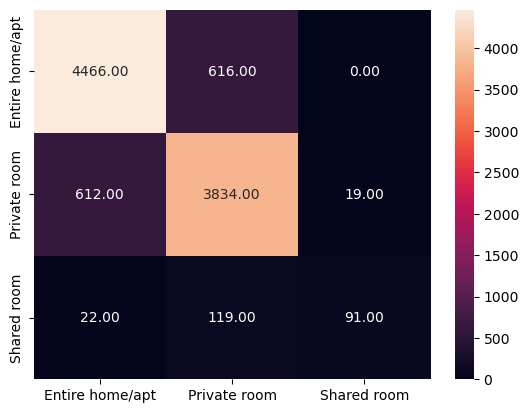

In [28]:
sns.heatmap(confusion_matrix(y_test,y_pred),annot = True, fmt ='.2f',xticklabels=pipeline.classes_,yticklabels=pipeline.classes_)


In [29]:
joblib.dump(pipeline,'Model_pipeline.pkl')

['Model_pipeline.pkl']